# Part B — The five decisions, computed (15 marks)

Every answer below is a number or a table **printed by the cell**, not an opinion. All data is synthetic, generated for CDB601220.

| Q | Decision |
|---|---|
| 1 | The size range `sizes=(lo, hi)` for the Part D1 bubble chart |
| 2 | Overplotting: opaque vs transparent vs hexbin vs 2-D KDE |
| 3 | Scaling (min–max / z-score / rank) and PCA |
| 4 | Project before you measure: spherical vs degree-space area, Mercator inflation |
| 5 | Small-area stability: funnel plot |

In [1]:
import os, sys, json, itertools
sys.path.insert(0, os.getcwd())          # notebook sits beside vizlib.py / geolib.py
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geolib as g                        # Week 5 toolkit (built on vizlib)
g.style_defaults()                        # Week 3 look, 300 dpi export default
DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
PAL = g.PALETTE

def corr_chain(df, cols):
    """geolib.corr_chain with one line changed: newer pandas hands back a read-only
    array, so np.fill_diagonal on r.values raises. Same greedy rule (slide 24)."""
    cols = list(cols)
    r = df[cols].corr().abs()
    a = r.to_numpy().copy(); np.fill_diagonal(a, 0.0)
    r = pd.DataFrame(a, index=cols, columns=cols)
    i, j = np.unravel_index(np.argmax(a), a.shape)
    order = [cols[i], cols[j]]
    while len(order) < len(cols):
        rest = [c for c in cols if c not in order]
        order.append(max(rest, key=lambda c: r.loc[order[-1], c]))
    return order

NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]

hi = pd.read_csv(DATA + "health_indicators.csv")
dh = pd.read_csv(DATA + "district_health.csv")

## B1 · The size range

In [2]:
pop = hi.pop_m.to_numpy()
print(f"population range: {pop.min()} – {pop.max()} M  -> ratio {pop.max()/pop.min():.0f}x")

LO, HI = 18, 1400                                  # points^2 — AREA, the unit ax.scatter(s=) takes
s = LO + (HI - LO) * (pop - pop.min()) / (pop.max() - pop.min())
d = np.sqrt(4 * s / np.pi)                         # diameter in points implied by an AREA of s pt^2

print(f"\nchosen sizes=(lo, hi) = ({LO}, {HI}) pt²")
print(f"  smallest mark: area {s.min():.0f} pt²  -> diameter {d.min():.1f} pt = {d.min()/72*25.4:.1f} mm")
print(f"  largest  mark: area {s.max():.0f} pt²  -> diameter {d.max():.1f} pt = {d.max()/72*25.4:.1f} mm")
print(f"  AREA ratio     {s.max()/s.min():.1f}x")
print(f"  DIAMETER ratio {d.max()/d.min():.2f}x   (= sqrt of the area ratio)")

# --- what the alternatives would have done, same biggest mark of 1400 pt²
s_prop = HI * pop / pop.max()                      # strictly proportional area (no floor)
print(f"\nstrictly proportional area, same max: smallest mark = {s_prop.min():.1f} pt² "
      f"({np.sqrt(4*s_prop.min()/np.pi):.1f} pt across); "
      f"{(s_prop < 12).sum()} of 60 countries fall below 12 pt² (≈ 3.9 pt, the smallest readable dot)")
r_wrong = HI * pop / pop.max()                     # if someone passed this as RADIUS-like quantity
print(f"if pop drove the RADIUS instead, area ratio would be {(pop.max()/pop.min())**2:,.0f}x "
      f"and the diameter ratio {pop.max()/pop.min():.0f}x")
assert np.allclose(np.pi * (d / 2) ** 2, s)        # I am passing AREA: pi r^2 recovers s exactly

population range: 0.6 – 353.4 M  -> ratio 589x

chosen sizes=(lo, hi) = (18, 1400) pt²
  smallest mark: area 18 pt²  -> diameter 4.8 pt = 1.7 mm
  largest  mark: area 1400 pt²  -> diameter 42.2 pt = 14.9 mm
  AREA ratio     77.8x
  DIAMETER ratio 8.82x   (= sqrt of the area ratio)

strictly proportional area, same max: smallest mark = 2.4 pt² (1.7 pt across); 19 of 60 countries fall below 12 pt² (≈ 3.9 pt, the smallest readable dot)
if pop drove the RADIUS instead, area ratio would be 346,921x and the diameter ratio 589x


**Justification of both ends**

* **Lower end, 18 pt²** — a dot ≈ 4.8 pt (1.7 mm) across stays a visible, colour-identifiable dot on a printed page. A strictly proportional scale with a 1,400 pt² maximum would give the smallest country 2.4 pt² (1.8 pt across): 
  the printed count above shows 19 of the 60 countries would sink below the readable threshold. A floor trades exact proportionality for legibility, and the **legend uses the same function with real populations**, so area still converts back to people.
* **Upper end, 1,400 pt²** — a circle ≈ 42 pt (15 mm) across; at that size Wessant (353 M) stays distinct from its neighbours on a ~10 × 6.5 inch plot.
* **Diameter ratio ≈ 8.8×** (area ratio 78×). The population range is 589×, so no *readable* area scale can hold the raw ratio: an honest area encoding compresses it — and is **declared** on the figure.
* **Area, not radius**: the assert shows π(d/2)² = the `s` I pass to `ax.scatter`. Driving the radius with population would have produced a 589× diameter ratio and a 346,921× area ratio.

**Note on the brief's self-check for Case 1** — see Part A: `s = pop_m**2` gives a **346,921×** area ratio, not 589× (589× is the *population* ratio), and 3 countries (not 9) fall below one point² — 9 countries have populations under 2.0 M, but only 3 are below 1.0 M, which is where `pop²` drops under 1 pt².

## B2 · Overplotting — four views of 9,000 points

9,000 points | 800 within 1.0 of (3.1, 3.0) | bulk 8,200


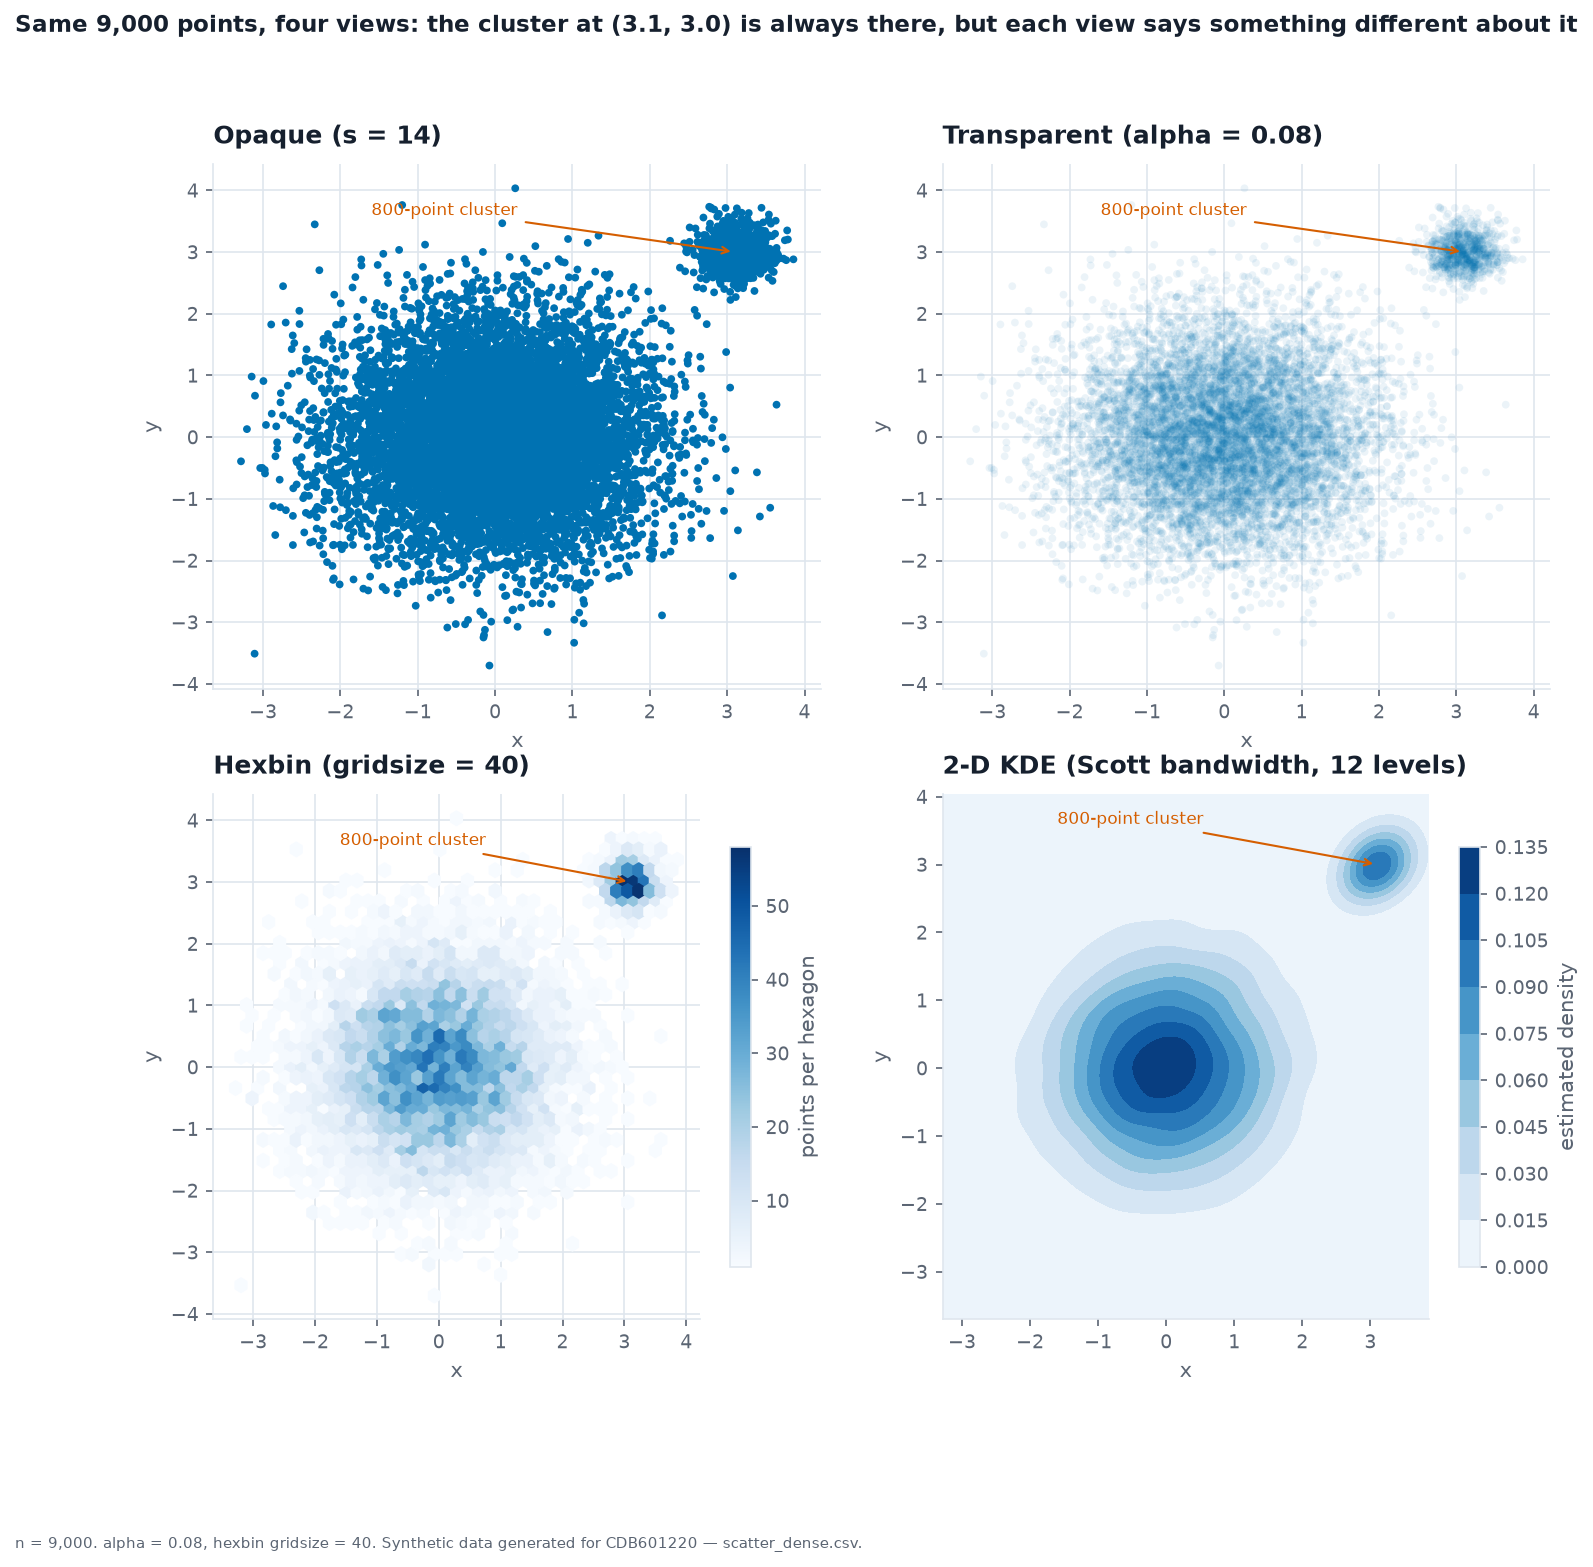

In [3]:
from scipy.stats import gaussian_kde
sd = pd.read_csv(DATA + "scatter_dense.csv")
x, y = sd.x.to_numpy(), sd.y.to_numpy()
CX, CY = 3.1, 3.0
r = np.hypot(x - CX, y - CY)
print(f"{len(sd):,} points | {int((r < 1.0).sum())} within 1.0 of ({CX}, {CY}) | bulk {int((r >= 1.0).sum()):,}")

ALPHA, GRID = 0.08, 40                        # declared parameters
fig, axs = plt.subplots(2, 2, figsize=(11.5, 10))
b = PAL["series"][0]
ax = axs[0, 0]; ax.scatter(x, y, s=14, color=b, edgecolor="none"); ax.set_title("Opaque (s = 14)")
ax = axs[0, 1]; ax.scatter(x, y, s=14, color=b, alpha=ALPHA, edgecolor="none"); ax.set_title(f"Transparent (alpha = {ALPHA})")
ax = axs[1, 0]
hb = ax.hexbin(x, y, gridsize=GRID, cmap=PAL["sequential"], mincnt=1)
fig.colorbar(hb, ax=ax, shrink=0.8, label="points per hexagon"); ax.set_title(f"Hexbin (gridsize = {GRID})")
ax = axs[1, 1]
xx, yy = np.mgrid[x.min():x.max():160j, y.min():y.max():160j]
kde = gaussian_kde(np.vstack([x, y]))
zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
cs = ax.contourf(xx, yy, zz, levels=12, cmap=PAL["sequential"])
fig.colorbar(cs, ax=ax, shrink=0.8, label="estimated density"); ax.set_title("2-D KDE (Scott bandwidth, 12 levels)")
for a in axs.ravel():
    a.set_xlabel("x"); a.set_ylabel("y")
    a.annotate("800-point cluster", (CX, CY), xytext=(-1.6, 3.6), fontsize=8, color=PAL["highlight"],
               arrowprops=dict(arrowstyle="->", color=PAL["highlight"], lw=1.0))
fig.suptitle("Same 9,000 points, four views: the cluster at (3.1, 3.0) is always there, but each view says something different about it", x=0.01, ha="left", fontweight="bold", fontsize=11)
g.save_fig(fig, FIG + "partB_overplot.png", note="n = 9,000. alpha = 0.08, hexbin gridsize = 40. Synthetic data generated for CDB601220 — scatter_dense.csv.")
plt.show()

In [4]:
# numbers behind the judgement
off, cnt = hb.get_offsets(), hb.get_array()
dd = np.hypot(off[:, 0] - CX, off[:, 1] - CY)
hex_cl, hex_bulk = cnt[dd < 0.8].max(), cnt[dd >= 0.8].max()
k_cl, k_bulk = kde([[CX], [CY]])[0], zz.max()
rows = [
 ("opaque",      "yes — as a separate clump", "no: a solid blob; 800 points look like the bulk's solid core, count unreadable"),
 ("transparent", "yes — separate and darker",  "yes, qualitatively: darker = denser; saturates if alpha is wrong"),
 ("hexbin",      "yes — and the densest cell", f"yes, quantitatively: cluster peak {hex_cl:.0f} per hexagon vs bulk peak {hex_bulk:.0f}"),
 ("2-D KDE",     "yes — as a second mode",     f"partly: smoothing flattens it — cluster density {k_cl:.3f} vs bulk peak {k_bulk:.3f} ({k_cl/k_bulk:.0%}) despite 10x fewer points"),
]
print(pd.DataFrame(rows, columns=["view", "800-pt cluster visible?", "what it tells you about the cluster"]).to_string(index=False))

       view    800-pt cluster visible?                                                                     what it tells you about the cluster
     opaque  yes — as a separate clump                          no: a solid blob; 800 points look like the bulk's solid core, count unreadable
transparent  yes — separate and darker                                        yes, qualitatively: darker = denser; saturates if alpha is wrong
     hexbin yes — and the densest cell                                        yes, quantitatively: cluster peak 58 per hexagon vs bulk peak 47
    2-D KDE     yes — as a second mode partly: smoothing flattens it — cluster density 0.104 vs bulk peak 0.131 (79%) despite 10x fewer points


**Which I would publish: the hexbin** (`gridsize = 40`), with its colour bar labelled *points per hexagon*. 
The cluster is visible in all four — it is far from the bulk — so visibility alone does not separate them. What separates them is *what the view lets the reader say about it*: 
the opaque plot hides how many points are in the blob (a solid dot is a solid dot, 800 or 8,000); alpha = 0.08 shows density but only as a shade the reader cannot convert to a number and that depends on the alpha I picked; 
the KDE smooths a tight 800-point cluster down to 79% of the bulk's peak although the bulk holds ten times more points (bandwidth is a hidden parameter that rewrites the answer); 
the hexbin counts points per cell, so the reader can see the cluster is the single densest region (58 per hexagon against 47 at the bulk's densest) — the finding the data contains. 
Declared parameters: **alpha = 0.08**, **hexbin gridsize = 40**, KDE Scott bandwidth with 12 contour levels.

## B3 · Scaling and dimension reduction

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
rows = []
for how in ("minmax", "zscore", "rank"):
    v = g.scale_frame(hi, NUM, how)["gdp_pc"]
    rows.append(dict(scaling=how, min=v.min(), median=v.median(), max=v.max(),
                     IQR=v.quantile(.75) - v.quantile(.25), std=v.std(ddof=0),
                     **{"share of the 60 in the lowest 10% of the axis range":
                        ((v - v.min()) / (v.max() - v.min()) < 0.10).mean()}))
tab = pd.DataFrame(rows).set_index("scaling")
print(tab.round(3).to_string())
mm = g.scale_frame(hi, NUM, "minmax")["gdp_pc"]
print(f"\nmin–max: {(mm < 0.10).sum()} of 60 countries sit below 0.10 on gdp_pc, median {mm.median():.3f}")
z = g.scale_frame(hi, NUM, "zscore")["gdp_pc"]
print(f"z-score: the outlier is at {z.max():+.2f} SD; the median country at {z.median():+.2f} SD; the 59 others span {z.nsmallest(59).max()-z.min():.2f} SD in total")
print(f"rank   : every country gets a distinct, evenly spread value — median {g.scale_frame(hi, NUM, 'rank')['gdp_pc'].median():.2f}")

Z = StandardScaler().fit_transform(hi[NUM])
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
print("\nPCA on standardised columns — explained variance ratio:", np.round(evr, 3))
print(f"PC1 {evr[0]:.1%}   PC2 {evr[1]:.1%}   first two = {evr[:2].sum():.1%}   missing = {1-evr[:2].sum():.1%}")
print(pd.DataFrame(pca.components_[:2].T, index=NUM, columns=["PC1", "PC2"]).round(2).to_string())

           min  median    max    IQR    std  share of the 60 in the lowest 10% of the axis range
scaling                                                                                         
minmax   0.000   0.017  1.000  0.028  0.127                                                0.967
zscore  -0.362  -0.225  7.501  0.220  1.000                                                0.967
rank     0.017   0.508  1.000  0.492  0.289                                                0.100

min–max: 58 of 60 countries sit below 0.10 on gdp_pc, median 0.017
z-score: the outlier is at +7.50 SD; the median country at -0.23 SD; the 59 others span 0.83 SD in total
rank   : every country gets a distinct, evenly spread value — median 0.51

PCA on standardised columns — explained variance ratio: [0.675 0.162 0.077 0.065 0.022]
PC1 67.5%   PC2 16.2%   first two = 83.7%   missing = 16.3%
                    PC1   PC2
gdp_pc             0.32  0.87
healthcare_access  0.51 -0.25
urban_pct          0.46 -0.07

**What each scaling does to the `gdp_pc` axis**

* **Min–max** — one country ($120,219, 9.2× the next) defines the top of the axis, so **58 of 60 countries squeeze below 0.10 and the median lands at 0.017**; the axis is almost flat.
* **z-score** — keeps relative gaps but the outlier sits at **+7.5 SD** while the median country is at −0.23 SD; the other 59 occupy a sliver of the range, so it is still outlier-sensitive.
* **Percentile rank** — immune to the outlier: median 0.51, IQR ≈ 0.5, evenly spread. The price is that it forgets how big the gaps were, so real min/max must be printed on the axis (which `g.pcp` does).

**PCA (standardised five columns):** PC1 explains **67.5%**, PC2 **16.2%**, so a two-axis picture holds **83.7%** of the variance and **misses 16.3%**. 
PC1 is a "development" axis (access, urban, age positive; case rate negative); PC2 is almost entirely GDP (loading 0.87) — which is exactly why GDP looks like a separate story in the two-axis view and why one outlier matters so much. 
The 16% that is missing is not noise to ignore: it is a whole independent dimension (GDP) that a 2-D projection would give a second, hard-to-read axis.

## B4 · Project before you measure

In [6]:
feats = g.read_geojson(DATA + "districts.geojson")
rows = []
for f in feats:
    ring = f["ring"]
    lon = np.array([p[0] for p in ring]); lat = np.array([p[1] for p in ring])
    sph = g.polygon_area_km2(ring)                                     # spherical excess, km²
    shoe = abs(0.5 * np.sum(lon * np.roll(lat, -1) - np.roll(lon, -1) * lat))   # degrees², "area" of raw lon/lat
    mx, my = g.mercator_xy(lon, lat)
    mer = abs(0.5 * np.sum(mx * np.roll(my, -1) - np.roll(mx, -1) * my))        # km² on the Mercator sheet
    rows.append(dict(code=f["code"], name=f["name"], lat=g.representative_point(ring)[1],
                     sph_km2=sph, shoelace_deg2=shoe, mercator_km2=mer))
A = pd.DataFrame(rows)
A["share_spherical"] = A.sph_km2 / A.sph_km2.sum()
A["share_shoelace"] = A.shoelace_deg2 / A.shoelace_deg2.sum()
A["share_distortion_%"] = (A.share_shoelace / A.share_spherical - 1) * 100
A["mercator_inflation"] = A.mercator_km2 / A.sph_km2
print(f"total spherical area {A.sph_km2.sum():,.0f} km²  |  all 24 areas agree with the shipped area_km2: "
      f"{np.allclose(A.sph_km2, dh.set_index('code').loc[A.code].area_km2.to_numpy(), rtol=2e-3)}")

north4 = A.nlargest(4, "lat")
print("\nfour northernmost districts:", north4.code.tolist(), "(lat %.1f–%.1f°N)" % (north4.lat.min(), north4.lat.max()))
print(f"  share of total area — spherical (correct): {north4.share_spherical.sum():.2%}")
print(f"  share of total area — shoelace on lon/lat: {north4.share_shoelace.sum():.2%}  "
      f"(+{(north4.share_shoelace.sum()/north4.share_spherical.sum()-1)*100:.1f}% relative)")
w = A.loc[A["share_distortion_%"].abs().idxmax()]
print(f"\nmost distorted single district: {w.code} {w['name']} — spherical {w.share_spherical:.3%} vs "
      f"shoelace {w.share_shoelace:.3%}  ({w['share_distortion_%']:+.1f}% relative)")
print(f"\nMercator area inflation, per district: min {A.mercator_inflation.min():.3f}x (south, {A.loc[A.mercator_inflation.idxmin(),'code']}) "
      f"to max {A.mercator_inflation.max():.3f}x (north, {A.loc[A.mercator_inflation.idxmax(),'code']})")
print(f"area-weighted across the federation: {A.mercator_km2.sum()/A.sph_km2.sum():.3f}x  "
      f"| far north inflated {A.mercator_inflation.max()/A.mercator_inflation.min():.2f}x more than far south")
print(f"check: sec²(lat) at 26°N = {1/np.cos(np.radians(26))**2:.3f}, at 35°N = {1/np.cos(np.radians(35))**2:.3f}")

total spherical area 1,026,075 km²  |  all 24 areas agree with the shipped area_km2: True

four northernmost districts: ['D21', 'D22', 'D19', 'D24'] (lat 34.9–35.0°N)
  share of total area — spherical (correct): 10.51%
  share of total area — shoelace on lon/lat: 11.08%  (+5.5% relative)

most distorted single district: D21 Ushkan — spherical 2.147% vs shoelace 2.266%  (+5.6% relative)

Mercator area inflation, per district: min 1.237x (south, D02) to max 1.492x (north, D21)
area-weighted across the federation: 1.340x  | far north inflated 1.21x more than far south
check: sec²(lat) at 26°N = 1.238, at 35°N = 1.490


**Findings.** Shoelace on raw longitude/latitude gives the four northernmost districts (D19, D21, D22, D24) **11.08%** of the area against the correct **10.51%** — a +5.5% relative overstatement; 
the single most distorted district is **D21 Ushkan (+5.6%)**. (The degree-space numbers also carry the wrong units — square *degrees*, not km² — which is why the comparison has to be made in shares.)
Mercator inflates area by sec²(latitude): the federation as a whole is drawn **1.34× too large**, with the far south (D01–D06 at ~26°N) at **1.24×** and the far north (~35°N) at **1.49×** — the north is inflated **1.2× more** than the south. 

**Why slide 34 demands an equal-area projection for a choropleth:** in a choropleth the *area* of each polygon is the encoding channel, and Mercator inflates the north by ~20% relative to the south, so identical rates would carry visibly more ink in the north — the projection would add a false north-south signal to the map before any data is plotted.

## B5 · Small-area stability — the funnel plot

In [7]:
from scipy import stats
sa = pd.read_csv(DATA + "smallarea_cases.csv")
sa["rate"] = sa.cases / sa.population * 1e5
pooled = sa.cases.sum() / sa.population.sum() * 1e5
fl = g.funnel_limits(sa.population, pooled)                      # 95% Poisson limits (normal approx)
lam = pooled / 1e5 * sa.population
sa["lo"] = np.maximum((lam - 1.96 * np.sqrt(lam)) / sa.population * 1e5, 0)
sa["hi"] = (lam + 1.96 * np.sqrt(lam)) / sa.population * 1e5
sa["outside"] = (sa.rate > sa.hi) | (sa.rate < sa.lo)
print(f"40 units | pooled rate {pooled:.2f} per 100,000 | outside the 95% funnel: {int(sa.outside.sum())} of 40")
print(sa[sa.outside][["unit", "cases", "population", "rate", "lo", "hi"]].round(2).to_string(index=False))

# exact-Poisson cross-check, because the normal limits go negative for small populations
sa["expected"] = lam
sa["p_upper"] = stats.poisson.sf(sa.cases - 1, lam)
sa["p_lower"] = stats.poisson.cdf(sa.cases, lam)
u = sa.loc[sa.unit == "U32"].iloc[0]
print(f"\nU32: {int(u.cases)} observed vs {u.expected:.2f} expected -> exact P(X >= 9) = {u.p_upper:.5f}; "
      f"x40 units (Bonferroni) = {min(u.p_upper*40,1):.4f}")
print("units with an exact one-sided p < 0.025 either way:", int(((sa.p_upper < .025) | (sa.p_lower < .025)).sum()))
print("zero-case units:", sa[sa.cases == 0].unit.tolist(), "(populations", sa[sa.cases == 0].population.tolist(), ")")
print("rate range of the 10 units > 100,000 people: %.1f – %.1f" % (sa[sa.population > 1e5].rate.min(), sa[sa.population > 1e5].rate.max()))

40 units | pooled rate 8.72 per 100,000 | outside the 95% funnel: 1 of 40
unit  cases  population  rate  lo    hi
 U32      9       22000 40.91 0.0 21.06

U32: 9 observed vs 1.92 expected -> exact P(X >= 9) = 0.00018; x40 units (Bonferroni) = 0.0070
units with an exact one-sided p < 0.025 either way: 1
zero-case units: ['U04', 'U12', 'U40'] (populations [5000, 39000, 5000] )
rate range of the 10 units > 100,000 people: 5.5 – 12.0


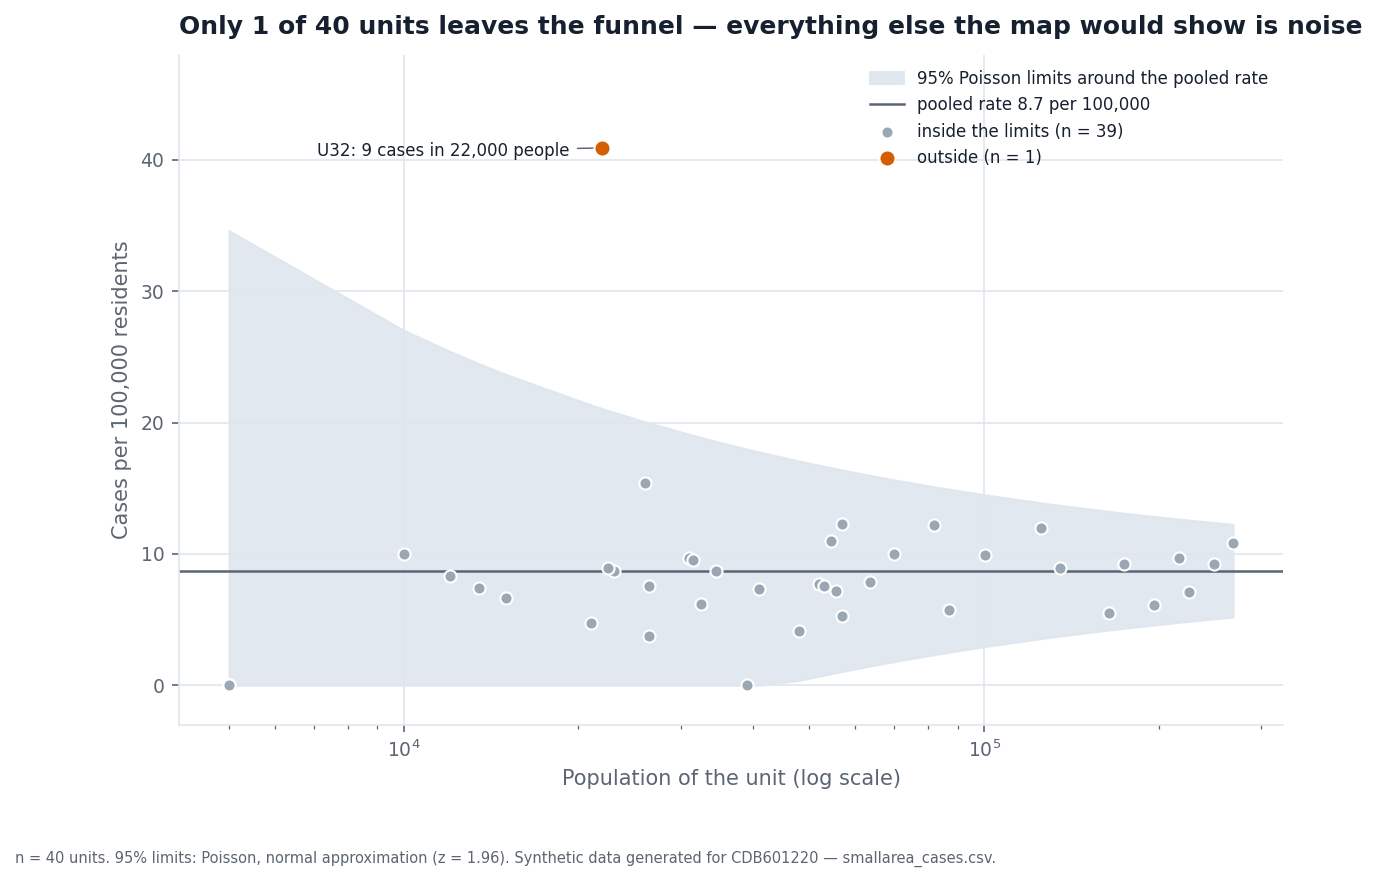

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 5.8))
ax.fill_between(fl.population, fl.lo, fl.hi, color=PAL["grid"], alpha=0.9, label="95% Poisson limits around the pooled rate", zorder=1)
ax.axhline(pooled, color=PAL["ink_soft"], lw=1.2, zorder=2, label=f"pooled rate {pooled:.1f} per 100,000")
ins, out = sa[~sa.outside], sa[sa.outside]
ax.scatter(ins.population, ins.rate, s=34, color=PAL["muted"], edgecolor="white", zorder=3, label=f"inside the limits (n = {len(ins)})")
ax.scatter(out.population, out.rate, s=60, color=PAL["highlight"], edgecolor="white", zorder=4, label=f"outside (n = {len(out)})")
for _, rr in out.iterrows():
    ax.annotate(f"{rr.unit}: {int(rr.cases)} cases in {int(rr.population):,} people", (rr.population, rr.rate),
                xytext=(-16, -4), ha="right", textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="-", color=PAL["ink_soft"], lw=.7))
ax.set_xscale("log"); ax.set_ylim(-3, 48)
ax.set_xlabel("Population of the unit (log scale)"); ax.set_ylabel("Cases per 100,000 residents")
ax.set_title("Only 1 of 40 units leaves the funnel — everything else the map would show is noise", loc="left")
ax.legend(loc="upper right", fontsize=8)
g.save_fig(fig, FIG + "partB_funnel.png", note="n = 40 units. 95% limits: Poisson, normal approximation (z = 1.96). Synthetic data generated for CDB601220 — smallarea_cases.csv.")
plt.show()

In [8]:
# minimum population at which a true rate of 9 per 100,000 can be told apart from 18 per 100,000
from scipy.optimize import brentq
r1, r2 = 9 / 1e5, 18 / 1e5
f1 = lambda N: r1 * N + 1.96 * np.sqrt(r1 * N) - r2 * N                    # funnel upper limit of 9 crosses 18
N1 = brentq(f1, 1e3, 1e7)
f2 = lambda N: (r1 * N + 1.96 * np.sqrt(r1 * N)) - (r2 * N - 1.96 * np.sqrt(r2 * N))   # two estimated rates, intervals just touch
N2 = brentq(f2, 1e3, 1e7)
print(f"(a) 18 falls above the 95% funnel limit of a known base rate of 9 once N >= {N1:,.0f}  (expected cases {r1*N1:.1f})")
print(f"(b) two *estimated* rates (9 and 18) have non-overlapping 95% intervals once N >= {N2:,.0f}  (expected cases at 9: {r1*N2:.0f})")
print(f"the smallest unit here is {sa.population.min():,}; {(sa.population < N1).sum()} of 40 units are below (a) and {(sa.population < N2).sum()} of 40 below (b)")

(a) 18 falls above the 95% funnel limit of a known base rate of 9 once N >= 42,684  (expected cases 3.8)
(b) two *estimated* rates (9 and 18) have non-overlapping 95% intervals once N >= 248,783  (expected cases at 9: 22)
the smallest unit here is 5,000; 19 of 40 units are below (a) and 39 of 40 below (b)


**What it tells us about the Part A case-6 map.** The funnel flags **1 of 40** units (U32) and nothing else. That is the point: every other rate on that map — the zeros (U04, U12, U40), U31's 15.4 from 4 cases, the top-ten list — sits inside the noise band, so ranking or shading them is shading Poisson noise. 
At U32's 22,000 residents only ~1.9 cases are expected, the 95% band runs up to **21.1 per 100,000 = 2.4× the national rate** by chance alone, and the normal-approximation lower limit is negative before clipping at zero (−3.6) — a sign the approximation is rough there, so I cross-checked with exact Poisson tails. 

U32 itself *is* outside (9 observed vs 1.9 expected, exact P(X ≥ 9) = 0.00018; ≈ 0.007 even after multiplying by 40 units). So the honest reading is "U32 warrants a second look with more data", **not** "U32 runs at 4.7× the national rate". The data dictionary adds that all 40 units share one true rate, which would make U32 a chance extreme — something nobody looking at the map could know, and why a ranked map with no uncertainty is unsafe to publish. 

**Minimum population:** against a known base rate of 9 per 100,000, a rate of 18 only leaves the 95% funnel once the unit has **≈ 42,700 people** (≈ 3.8 expected cases). If both rates must be *estimated* from the unit's own data, their intervals only stop overlapping at **≈ 249,000 people** — larger than all but one of the 40 units. Below those populations a rate of 9 and a rate of 18 cannot be told apart at all.